WEB DOCUMENT COLLECTION
Total documents: 15


,ID,Title,Content
0,D1,Machine Learning,Machine learning is a branch of artificial int...
1,D2,Deep Learning,Deep learning uses neural networks for image r...
2,D3,Artificial Intelligence,Artificial intelligence enables machines to pe...
3,D4,Data Science,"Data science involves data analysis, statistic..."
4,D5,Web Development,"Web development involves HTML, CSS, JavaScript..."
5,D6,Python Programming,Python is a programming language used in machi...
6,D7,Natural Language Processing,Natural language processing uses machine learn...
7,D8,Computer Networks,Computer networks connect devices and allow co...
8,D9,Machine Learning Applications,"Machine learning is used in healthcare, bankin..."
9,D10,Big Data Analytics,Big data analytics processes large datasets to...



WEB LINK STRUCTURE
Total web pages: 15
Total links: 33

TF-IDF MATRIX SHAPE: (15, 92)

Enter your search query: Machine Learning

SEARCH RESULTS


,Rank,ID,Title,Relevance,PageRank,Final_Score
0,1,D1,Machine Learning,0.5689,0.1466,0.6982
1,2,D9,Machine Learning Applications,0.4794,0.0574,0.4328
2,3,D3,Artificial Intelligence,0.2212,0.1278,0.4121
3,4,D4,Data Science,0.2150,0.0938,0.3306
4,5,D2,Deep Learning,0.1908,0.0920,0.3096
5,6,D8,Computer Networks,0.0000,0.1196,0.2388
6,7,D7,Natural Language Processing,0.1725,0.0462,0.1926
7,8,D15,Recommendation Systems,0.2106,0.0263,0.1740
8,9,D6,Python Programming,0.2047,0.0162,0.1470
9,10,D11,Computer Vision,0.0909,0.0491,0.1421


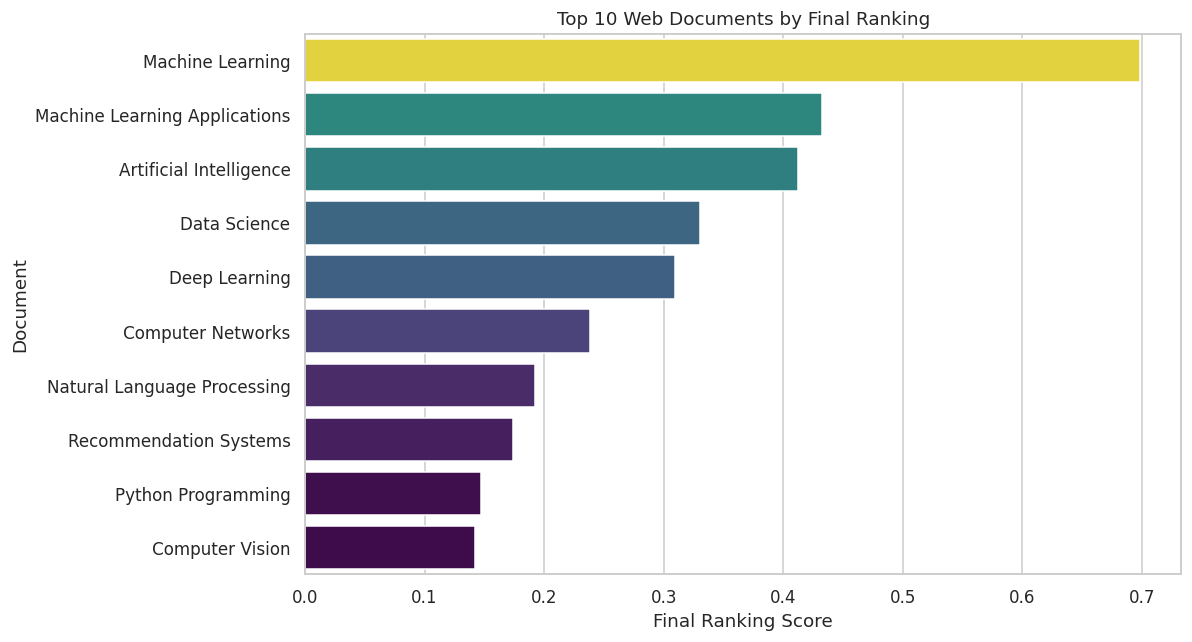

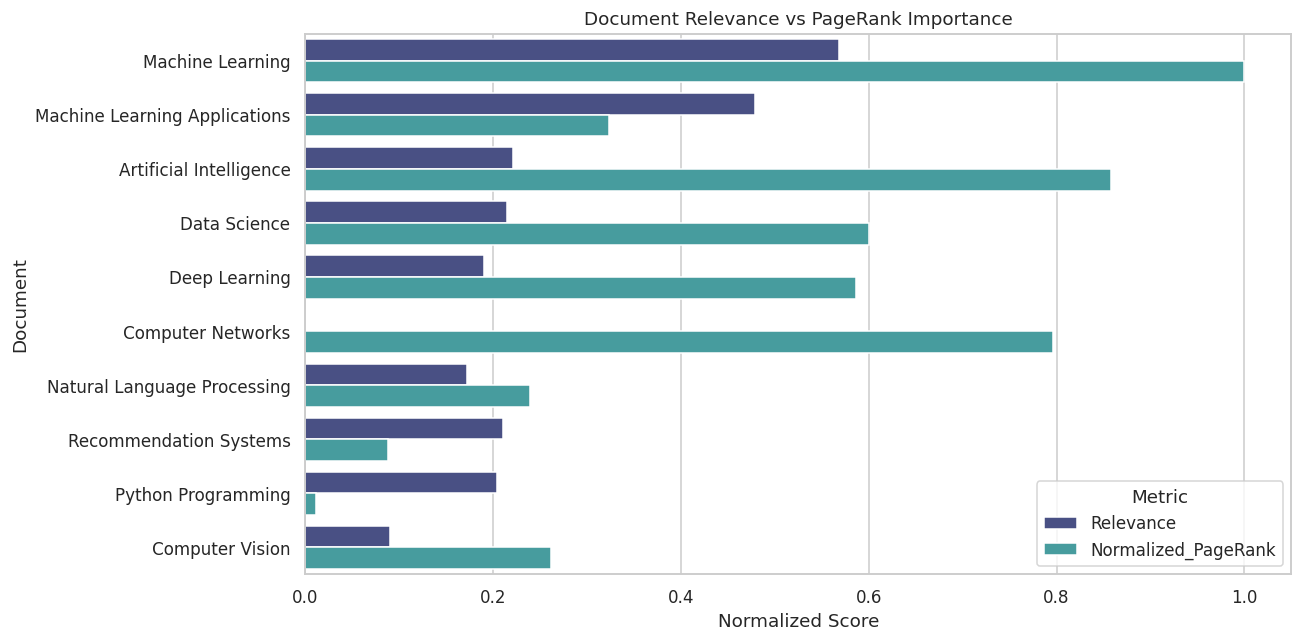

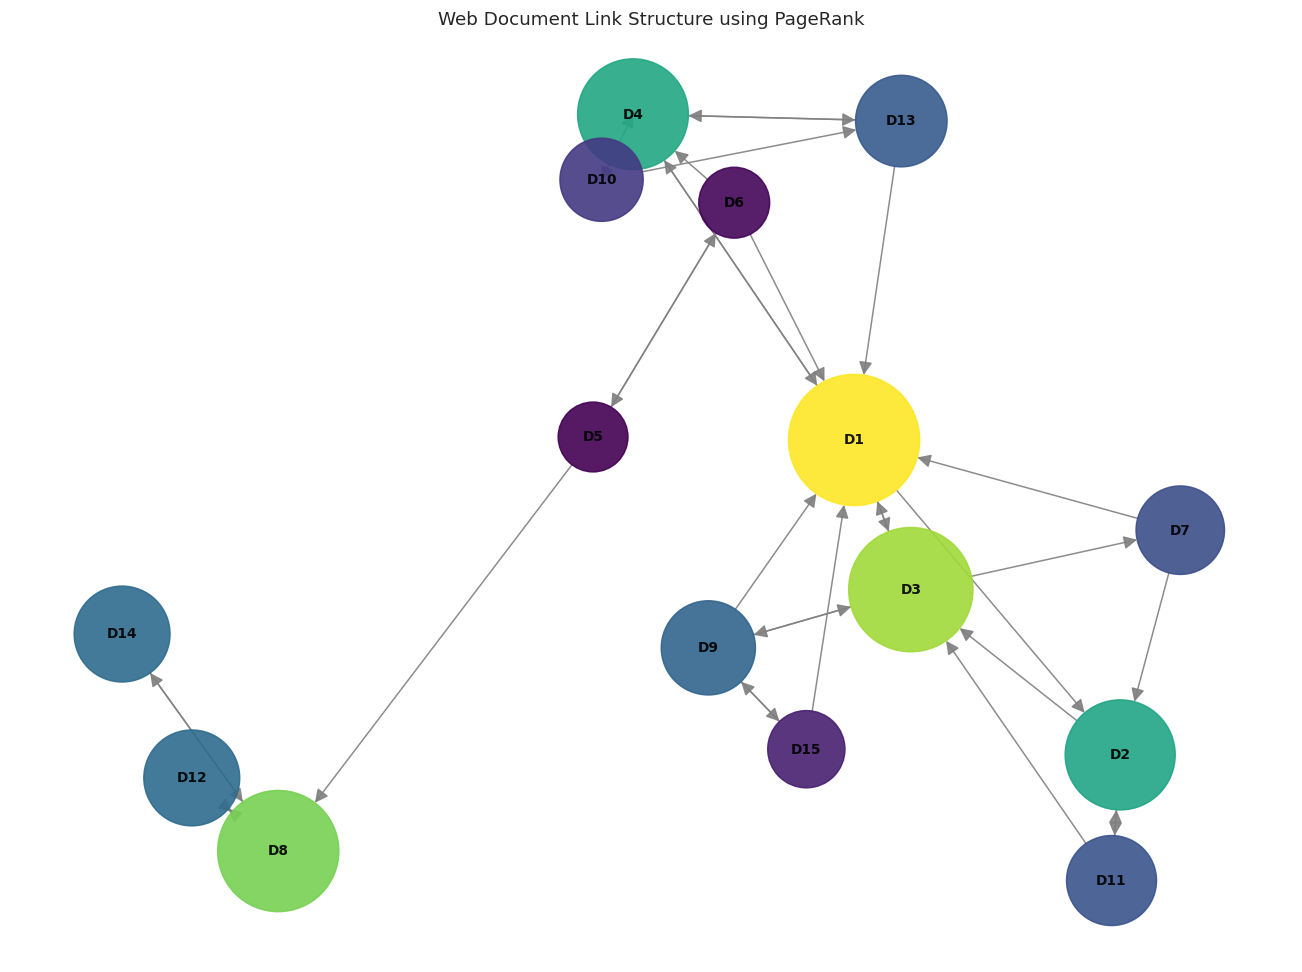

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

documents = [
    {"ID": "D1", "Title": "Machine Learning",
     "Content": "Machine learning is a branch of artificial intelligence that uses algorithms to learn from data."},
    {"ID": "D2", "Title": "Deep Learning",
     "Content": "Deep learning uses neural networks for image recognition, speech processing and artificial intelligence."},
    {"ID": "D3", "Title": "Artificial Intelligence",
     "Content": "Artificial intelligence enables machines to perform intelligent tasks using machine learning and algorithms."},
    {"ID": "D4", "Title": "Data Science",
     "Content": "Data science involves data analysis, statistics, visualization and machine learning techniques."},
    {"ID": "D5", "Title": "Web Development",
     "Content": "Web development involves HTML, CSS, JavaScript and building interactive websites."},
    {"ID": "D6", "Title": "Python Programming",
     "Content": "Python is a programming language used in machine learning, data science and web development."},
    {"ID": "D7", "Title": "Natural Language Processing",
     "Content": "Natural language processing uses machine learning to understand and process human language."},
    {"ID": "D8", "Title": "Computer Networks",
     "Content": "Computer networks connect devices and allow communication through internet protocols."},
    {"ID": "D9", "Title": "Machine Learning Applications",
     "Content": "Machine learning is used in healthcare, banking, recommendation systems and fraud detection."},
    {"ID": "D10", "Title": "Big Data Analytics",
     "Content": "Big data analytics processes large datasets to discover useful patterns and business insights."},
    {"ID": "D11", "Title": "Computer Vision",
     "Content": "Computer vision uses deep learning and artificial intelligence to analyse images and videos."},
    {"ID": "D12", "Title": "Cloud Computing",
     "Content": "Cloud computing provides storage, servers and computing resources over the internet."},
    {"ID": "D13", "Title": "Data Mining",
     "Content": "Data mining extracts useful patterns and knowledge from large datasets using algorithms."},
    {"ID": "D14", "Title": "Cyber Security",
     "Content": "Cyber security protects computer networks, systems and data from digital attacks."},
    {"ID": "D15", "Title": "Recommendation Systems",
     "Content": "Recommendation systems use machine learning to suggest relevant products and services to users."}]
df = pd.DataFrame(documents)
print("WEB DOCUMENT COLLECTION")
print("Total documents:", len(df))
display(df[["ID", "Title", "Content"]])

links = [
    ("D1", "D2"), ("D1", "D3"), ("D1", "D4"),
    ("D2", "D3"), ("D2", "D11"),
    ("D3", "D1"), ("D3", "D7"), ("D3", "D9"),
    ("D4", "D1"), ("D4", "D10"), ("D4", "D13"),
    ("D5", "D6"), ("D5", "D8"),
    ("D6", "D1"), ("D6", "D4"), ("D6", "D5"),
    ("D7", "D1"), ("D7", "D2"),
    ("D8", "D12"), ("D8", "D14"),
    ("D9", "D1"), ("D9", "D3"), ("D9", "D15"),
    ("D10", "D4"), ("D10", "D13"),
    ("D11", "D2"), ("D11", "D3"),
    ("D12", "D8"),
    ("D13", "D4"), ("D13", "D1"),
    ("D14", "D8"),
    ("D15", "D1"), ("D15", "D9")]

G = nx.DiGraph()
G.add_nodes_from(df["ID"])
G.add_edges_from(links)
print("\nWEB LINK STRUCTURE")
print("Total web pages:", G.number_of_nodes())
print("Total links:", G.number_of_edges())

pagerank = nx.pagerank(G, alpha=0.85)
df["PageRank"] = df["ID"].map(pagerank)

df["Text"] = df["Title"] + " " + df["Content"]
vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(df["Text"])
print("\nTF-IDF MATRIX SHAPE:", tfidf_matrix.shape)

query = input("\nEnter your search query: ")
query_vector = vectorizer.transform([query])

similarity = cosine_similarity(query_vector, tfidf_matrix).flatten()
df["Relevance"] = similarity

if df["PageRank"].max() > df["PageRank"].min():
    df["Normalized_PageRank"] = (
        (df["PageRank"] - df["PageRank"].min()) /
        (df["PageRank"].max() - df["PageRank"].min()))
else:
    df["Normalized_PageRank"] = 0

df["Final_Score"] = (
    0.7 * df["Relevance"] +
    0.3 * df["Normalized_PageRank"])
results = df.sort_values("Final_Score", ascending=False).reset_index(drop=True)
results.insert(0, "Rank", range(1, len(results) + 1))
print("\nSEARCH RESULTS")
display(results[[
        "Rank", "ID", "Title",
        "Relevance", "PageRank", "Final_Score"]].round(4))

top_results = results.head(10)
plt.figure(figsize=(11, 6))
sns.barplot(
    data=top_results,
    x="Final_Score",
    y="Title",
    hue="Final_Score",
    palette="viridis",
    legend=False)
plt.title("Top 10 Web Documents by Final Ranking")
plt.xlabel("Final Ranking Score")
plt.ylabel("Document")
plt.tight_layout()
plt.show()

comparison = top_results.melt(
    id_vars="Title",
    value_vars=["Relevance", "Normalized_PageRank"],
    var_name="Metric",
    value_name="Score")
plt.figure(figsize=(12, 6))
sns.barplot(
    data=comparison,
    x="Score",
    y="Title",
    hue="Metric",
    palette="mako")
plt.title("Document Relevance vs PageRank Importance")
plt.xlabel("Normalized Score")
plt.ylabel("Document")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G, seed=42, k=0.8)
node_values = [pagerank[node] for node in G.nodes()]
nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_color=node_values,
    cmap=plt.cm.viridis,
    node_size=[1500 + 40000 * pagerank[node] for node in G.nodes()],
    font_size=9,
    font_weight="bold",
    arrows=True,
    arrowsize=18,
    edge_color="gray",
    alpha=0.9)
plt.title("Web Document Link Structure using PageRank")
plt.axis("off")
plt.tight_layout()
plt.show()